# 03 — Severity trade-offs: frequent small disruptions vs rare severe events

**Why this notebook.** The three stakeholders want different things:

| Stakeholder | Wants | What that means for a model |
|---|---|---|
| VP Operations | earlier escalation, less disruption | catch *many* service-affecting incidents early |
| CFO | prioritisation, confidence, financial burden | focus on the incidents that cost the most; know how sure we are |
| Public Affairs / Safety | user impact, communication risk, rare severe events | do not miss the rare, long, safety-relevant events |

Our working position is to **prioritise the rare, severe events** (financial burden and
safety), accepting that this may mean catching fewer of the small disruptions. This
notebook checks whether the data actually forces that choice, i.e. whether a
*natural trade-off* exists between the two goals, before we build any model.

**Questions**
1. How is the total delay burden split between frequent short incidents and rare long ones?
2. How rare do "severe" events get as the duration threshold rises?
3. Do severe events look different (different symptoms) from ordinary service-affecting ones?
4. How does duration relate to the safety-response flags (evacuation, emergency team)?
5. If we escalate a fixed share of incidents, does tuning for severe events cost us
   recall on ordinary ones?
6. Is the rare-event count stable enough over time to measure with confidence?

Scope: **train incidents only** (notebook 01 showed station incidents never interrupt
service). Parsing is minimal, as in notebook 02.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in code/exploration/; config.py lives in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

BUCKETS = ["02 min et moins", "03 à 04 min", "05 à 09 min", "10 à 14 min",
           "15 à 19 min", "20 à 24 min", "25 à 29 min", "30 min et plus"]
SHORT_LABELS = ["<=2", "3-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30+"]

## 1. Load train incidents and build a delay-minutes proxy

The duration is only published in buckets, so "total delay minutes" has to be
approximated:

* buckets below 30 min → the bucket **midpoint** (e.g. `05 à 09 min` → 7);
* `30 min et plus` has no upper bound → the **recorded duration** (resumption time minus
  start time), floored at 30.

Why not use the recorded duration everywhere? Notebook 01 (section 10) showed it has
long, implausible tails inside the short buckets (e.g. 1,202 minutes in the
"2 minutes or less" bucket). The bucket is the official measure, so we trust it where it
is bounded.

**Limitation.** These are minutes of *service delay*, not *passenger*-minutes. The
data has no ridership or cost information, so "financial burden" can only be
approximated by delay duration.

In [2]:
incidents = pd.read_csv(config.INCIDENTS_RAW, sep=";", encoding="utf-8-sig",
                        dtype=str, keep_default_na=False)
train = incidents[incidents["Type d'incident"] == "T"].copy()

train["bucket"] = pd.Categorical(train["Incident en minutes"], categories=BUCKETS, ordered=True)
train["year"] = train["Année civile"].astype(int)


def to_minutes(hhmm: pd.Series) -> pd.Series:
    # "25:26" or "25:26:00" -> minutes after the start of the service day (see notebook 01).
    parts = hhmm.str.split(":", expand=True)
    return parts[0].astype(int) * 60 + parts[1].astype(int)


recorded = to_minutes(train["Heure de reprise"]) - to_minutes(train["Heure de l'incident"])

# Delay-minutes proxy: bucket midpoint, or recorded duration (>= 30) for the open bucket.
MIDPOINTS = dict(zip(BUCKETS[:-1], [1, 3.5, 7, 12, 17, 22, 27]))
is_30plus = train["bucket"] == "30 min et plus"
train["delay_min"] = train["Incident en minutes"].map(MIDPOINTS).astype(float)
train.loc[is_30plus, "delay_min"] = recorded[is_30plus].clip(lower=30)

print(f"Train incidents: {len(train):,}")
print(f"Recorded duration of 30+ incidents: median {recorded[is_30plus].median():.0f} min, "
      f"90th percentile {recorded[is_30plus].quantile(0.9):.0f} min")

Train incidents: 29,167
Recorded duration of 30+ incidents: median 49 min, 90th percentile 94 min


## 2. Frequency vs burden

If every incident cost about the same, a bucket's share of incidents would equal its
share of delay minutes. Compare the two.

In [3]:
burden = train.groupby("bucket", observed=True).agg(incidents=("delay_min", "size"),
                                                    delay_min=("delay_min", "sum"))
burden["% of incidents"] = 100 * burden["incidents"] / burden["incidents"].sum()
burden["% of delay minutes"] = 100 * burden["delay_min"] / burden["delay_min"].sum()
burden.index = SHORT_LABELS
burden.round(1)

,incidents,delay_min,% of incidents,% of delay minutes
<=2,16450,16450.0,56.4,12.9
3-4,6304,22064.0,21.6,17.3
5-9,4377,30639.0,15.0,24.1
10-14,933,11196.0,3.2,8.8
15-19,299,5083.0,1.0,4.0
20-24,173,3806.0,0.6,3.0
25-29,107,2889.0,0.4,2.3
30+,524,35133.0,1.8,27.6


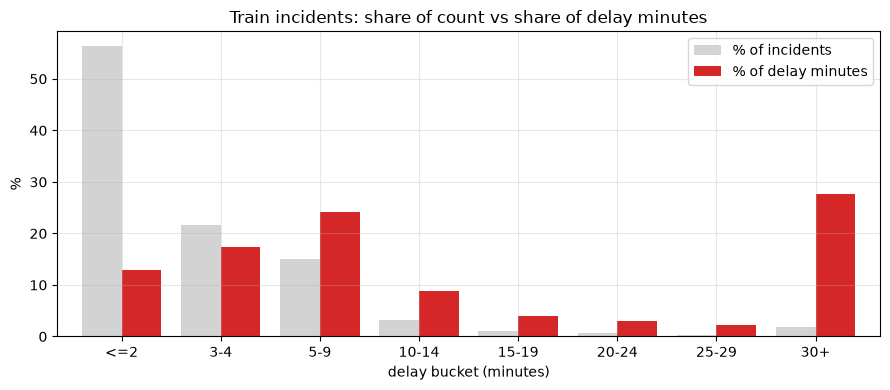

In [4]:
# Plot: share of incidents vs share of delay minutes, by duration bucket.
fig, ax = plt.subplots(figsize=(9, 4))
burden[["% of incidents", "% of delay minutes"]].plot.bar(
    ax=ax, color=["lightgray", "tab:red"], width=0.8)
ax.set_title("Train incidents: share of count vs share of delay minutes")
ax.set_xlabel("delay bucket (minutes)")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Finding.** The burden is concentrated at the two ends. Incidents of 30+ minutes are
under **2%** of train incidents but carry over **a quarter** of all delay minutes, more
than any other bucket. The 2-minutes-or-less bucket is over half of all incidents
but about an eighth of the minutes. Ranked by burden per incident, the rare tail
matters most, which supports the CFO / Safety focus.

## 3. How rare is "severe"? Prevalence by threshold

The higher the bar for "major", the closer the target is to what the CFO and Safety
care about, but the fewer examples a model has to learn from and the noisier the
evaluation gets.

In [5]:
thresholds = {">= 5 min": "05 à 09 min", ">= 10 min": "10 à 14 min",
              ">= 15 min": "15 à 19 min", ">= 20 min": "20 à 24 min",
              ">= 30 min": "30 min et plus"}

n_years = train["year"].nunique() - 0.25   # 2025 covers January to September only
prevalence = pd.DataFrame({
    name: {
        "positives": (train["bucket"] >= bucket).sum(),
        "% of train incidents": 100 * (train["bucket"] >= bucket).mean(),
        "positives per year": (train["bucket"] >= bucket).sum() / n_years,
        "% of delay minutes": 100 * train.loc[train["bucket"] >= bucket, "delay_min"].sum()
                              / train["delay_min"].sum(),
    }
    for name, bucket in thresholds.items()
}).T.round(1)
prevalence

,positives,% of train incidents,positives per year,% of delay minutes
>= 5 min,6413.0,22.0,950.1,69.7
>= 10 min,2036.0,7.0,301.6,45.7
>= 15 min,1103.0,3.8,163.4,36.9
>= 20 min,804.0,2.8,119.1,32.9
>= 30 min,524.0,1.8,77.6,27.6


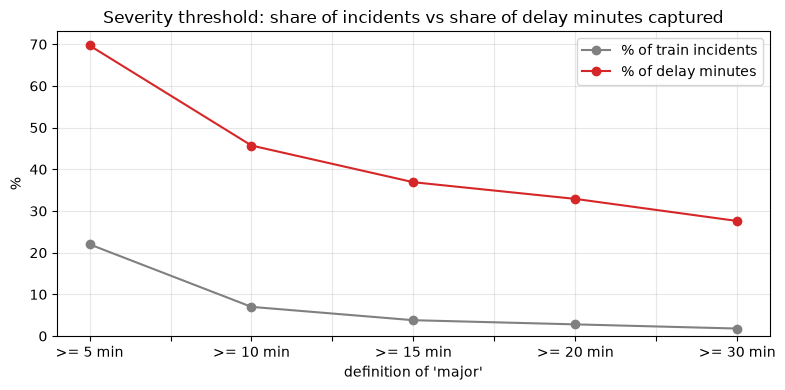

In [6]:
# Plot: as the threshold rises, events get rarer much faster than their burden share falls.
fig, ax = plt.subplots(figsize=(8, 4))
prevalence[["% of train incidents", "% of delay minutes"]].plot(
    ax=ax, marker="o", color=["gray", "tab:red"])
ax.set_title("Severity threshold: share of incidents vs share of delay minutes captured")
ax.set_xlabel("definition of 'major'")
ax.set_ylabel("%")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

**Finding.** Moving the bar from 5 to 30 minutes divides the number of positive cases by
about 12, but the share of delay minutes captured falls only by a factor of about 2.5
(from ~70% to ~28%). Each severe event is worth far more burden than a moderate one.
At 30+ minutes there are roughly **80 events a year**: enough to rank and evaluate,
but a single test year holds well under 100 positives, so metrics will carry real
uncertainty.

## 4. Do severe events look different?

If 30+ minute events were just "more of the same", a model built for 5+ minute delays
would also find the severe ones. Compare the symptom mix, which is recorded at report
time and so is usable for early escalation.

In [7]:
service_affecting = train["bucket"] >= "05 à 09 min"
severe = train["bucket"] == "30 min et plus"

symptom_mix = pd.DataFrame({
    "all train incidents": train["Symptome"].value_counts(normalize=True),
    ">= 5 min": train.loc[service_affecting, "Symptome"].value_counts(normalize=True),
    "30+ min": train.loc[severe, "Symptome"].value_counts(normalize=True),
}).fillna(0).mul(100).round(1).sort_values("30+ min", ascending=False)
symptom_mix

,all train incidents,>= 5 min,30+ min
Symptome,,,
Clientèle,44.9,39.7,42.0
"Feu, fumée, odeur, produit, etc...",4.3,4.0,26.1
Équipements fixes,13.3,20.2,20.0
Matériel roulant,26.6,31.9,11.1
Divers,0.3,0.5,0.4
Exploitation stations,3.2,0.2,0.4
#N/A,0.3,0.2,0.0
Exploitation trains,7.1,3.4,0.0


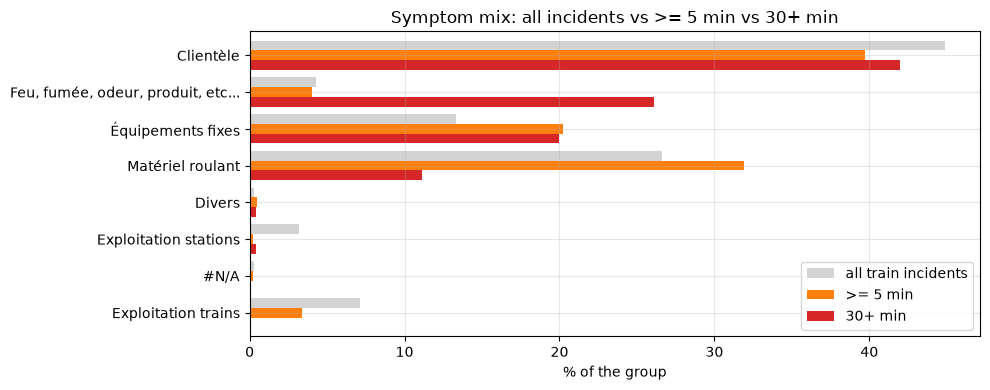

In [8]:
# Plot: symptom shares side by side for the three populations.
fig, ax = plt.subplots(figsize=(10, 4))
symptom_mix.plot.barh(ax=ax, color=["lightgray", "tab:orange", "tab:red"], width=0.8)
ax.invert_yaxis()
ax.set_title("Symptom mix: all incidents vs >= 5 min vs 30+ min")
ax.set_xlabel("% of the group")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Finding: this is the trade-off.**
* **Fire / smoke / odour** is a small share of service-affecting incidents but around a
  quarter of the 30+ minute ones.
* **Rolling stock** (`Matériel roulant`) is the reverse: about a third of 5+ minute
  incidents, but a much smaller share of the severe ones.
* So a model optimised for 5+ minute delays will learn to flag rolling-stock problems;
  a model optimised for 30+ minutes will learn to flag fire/smoke. They prioritise
  *different incidents*.

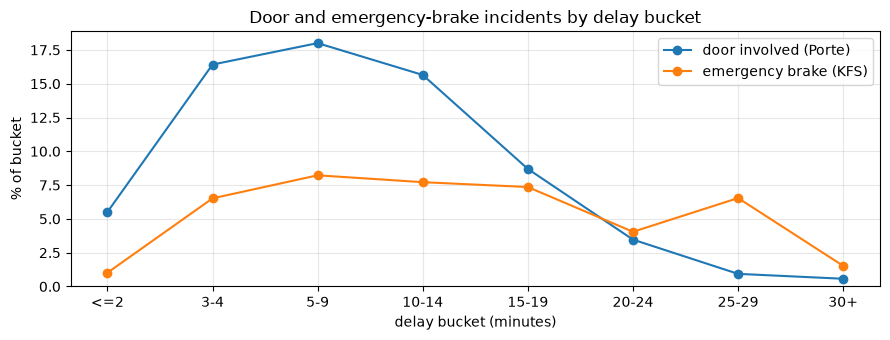

In [9]:
# What do the *small* disruptions look like? Share of each bucket with a door problem
# or a customer emergency-brake pull (both known at report time).
small_profile = pd.DataFrame({
    "door involved (Porte)": train.groupby("bucket", observed=True)["Porte"].apply(lambda s: (s == "1").mean()),
    "emergency brake (KFS)": train.groupby("bucket", observed=True)["KFS"].apply(lambda s: (s == "1").mean()),
}).mul(100)
small_profile.index = SHORT_LABELS

fig, ax = plt.subplots(figsize=(9, 3.5))
small_profile.plot(ax=ax, marker="o")
ax.set_title("Door and emergency-brake incidents by delay bucket")
ax.set_xlabel("delay bucket (minutes)")
ax.set_ylabel("% of bucket")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

Door problems and emergency-brake pulls peak in the **3 to 14 minute** range and almost
vanish at 30+. They are the typical "frequent, moderate" disruption. Focusing on the
severe tail means giving them a lower priority.

## 5. Duration vs safety response

The response flags are recorded during or after the incident, so they cannot be used
as model *inputs* (notebook 01). They are still useful to check whether a long
delay is also a *safety-relevant* event.

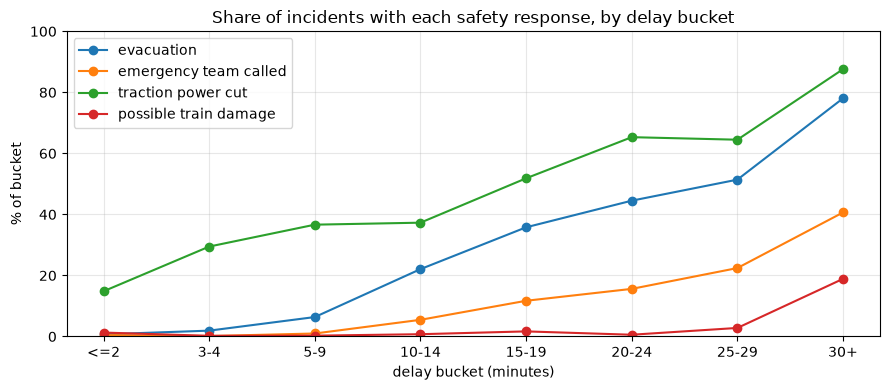

In [10]:
response = pd.DataFrame({
    "evacuation":             train["Évacuation"].ne("#"),
    "emergency team called":  train["Urgence métro"].eq("1"),
    "traction power cut":     train["CAT"].eq("1"),
    "possible train damage":  train["Dommage matériel"].eq("1"),
}).groupby(train["bucket"], observed=True).mean().mul(100)
response.index = SHORT_LABELS

fig, ax = plt.subplots(figsize=(9, 4))
response.plot(ax=ax, marker="o")
ax.set_title("Share of incidents with each safety response, by delay bucket")
ax.set_xlabel("delay bucket (minutes)")
ax.set_ylabel("% of bucket")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [11]:
# Overlap between "severe by duration" and "safety response" (evacuation or emergency team).
safety_response = train["Évacuation"].ne("#") | train["Urgence métro"].eq("1")
pd.crosstab(severe.rename("30+ min"), safety_response.rename("evacuation or emergency team"),
            margins=True)

evacuation or emergency team,False,True,All
30+ min,,,
False,27550,1093,28643
True,102,422,524
All,27652,1515,29167


**Finding.** Every response flag rises steeply with duration: most 30+ minute incidents
involve an evacuation and a traction power cut. So a duration-based "major" target
mostly picks up the safety-relevant events too, and the CFO and Safety goals point the
same way. The overlap is not perfect, though: about a thousand incidents have an
evacuation or emergency team call but last under 30 minutes. A safety-only target would
be a different, larger set; we note it as an alternative definition.

## 6. The escalation trade-off, made concrete

A simple, model-free test. Suppose the control centre can escalate a fixed share of
incidents (an "alert budget"). We rank incidents with a **lookup table** of historical
rates by *symptom × line*, both known at report time, and ask how many 5+ minute and
30+ minute incidents each ranking catches.

To keep this honest, the rates are learned on **2019–2022** and tested on
**2023–2025**, the same kind of time split the real model will use. Two rankings:

* **tuned for 5+ min**: groups ordered by their historical 5+ minute rate
* **tuned for 30+ min**: groups ordered by their historical 30+ minute rate

In [12]:
train["group"] = train["Symptome"] + " | " + train["Ligne"]
train["y_5"] = service_affecting
train["y_30"] = severe

past = train[train["year"] <= 2022]
future = train[train["year"] >= 2023]


def capture_curve(score_target: str, eval_target: str) -> pd.DataFrame:
    # Rank groups by their past rate of `score_target`, then trace, on future incidents,
    # the share of incidents escalated (x) vs the share of `eval_target` caught (y).
    # Working at group level treats ties fairly: a whole group is escalated at once,
    # and the curve is linear in between.
    past_rate = past.groupby("group")[score_target].mean()
    score = future["group"].map(past_rate).fillna(past[score_target].mean())
    by_group = (future.assign(score=score)
                .groupby("group").agg(score=("score", "first"),
                                      n=(eval_target, "size"),
                                      hits=(eval_target, "sum"))
                .sort_values("score", ascending=False))
    curve = pd.DataFrame({
        "escalated": by_group["n"].cumsum() / by_group["n"].sum(),
        "caught": by_group["hits"].cumsum() / by_group["hits"].sum(),
    })
    # Start the curve at (0, 0).
    return pd.concat([pd.DataFrame({"escalated": [0.0], "caught": [0.0]}), curve],
                     ignore_index=True)


curves = {(score, evaluated): capture_curve(score, evaluated)
          for score in ["y_5", "y_30"] for evaluated in ["y_5", "y_30"]}
print(f"Test years: {len(future):,} train incidents, "
      f"{future['y_5'].sum():,} >= 5 min, {future['y_30'].sum():,} 30+ min")

Test years: 12,606 train incidents, 2,954 >= 5 min, 227 30+ min


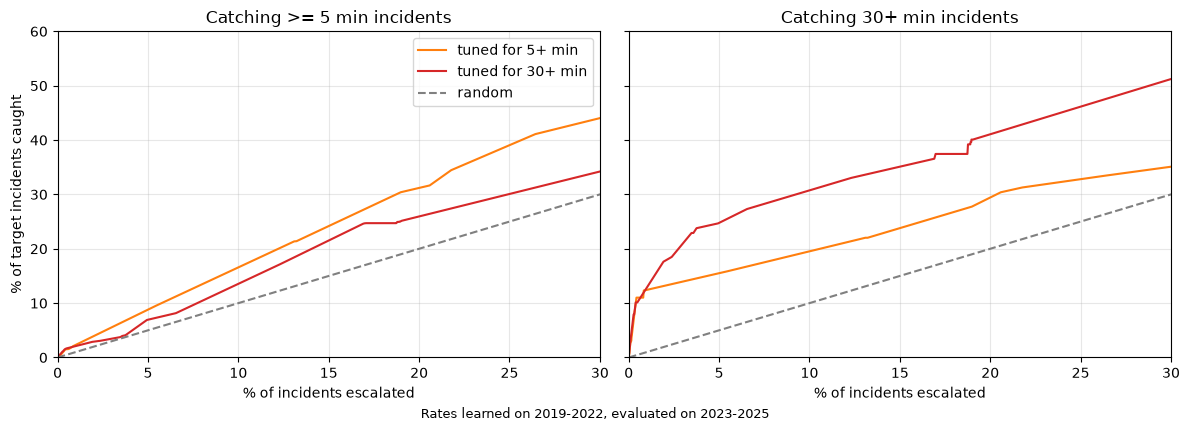

In [13]:
# Plot: capture curves. Left panel = how many 5+ min incidents each ranking catches;
# right panel = how many 30+ min incidents each ranking catches.
RANKING_STYLE = {"y_5": ("tuned for 5+ min", "tab:orange"),
                 "y_30": ("tuned for 30+ min", "tab:red")}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, evaluated, title in zip(axes, ["y_5", "y_30"],
                                ["Catching >= 5 min incidents", "Catching 30+ min incidents"]):
    for score, (label, color) in RANKING_STYLE.items():
        curve = curves[(score, evaluated)]
        ax.plot(100 * curve["escalated"], 100 * curve["caught"], color=color, label=label)
    ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="random")
    ax.set_xlim(0, 30)   # only small alert budgets are realistic
    ax.set_ylim(0, 60)
    ax.set_title(title)
    ax.set_xlabel("% of incidents escalated")
axes[0].set_ylabel("% of target incidents caught")
axes[0].legend()
fig.suptitle("Rates learned on 2019-2022, evaluated on 2023-2025", fontsize=9, y=0.02)
plt.tight_layout()
plt.show()

In [14]:
# Table: the same curves read at a few alert budgets (linear interpolation between groups).
budgets = [0.02, 0.05, 0.10, 0.20]
rows = {}
for score, (label, _) in RANKING_STYLE.items():
    for evaluated, name in [("y_5", "% of >= 5 min caught"), ("y_30", "% of 30+ min caught")]:
        curve = curves[(score, evaluated)]
        rows[(label, name)] = 100 * np.interp(budgets, curve["escalated"], curve["caught"])

pd.DataFrame(rows, index=[f"escalate {int(100 * b)}%" for b in budgets]).round(1)

tuned for 5+ min                        tuned for 30+ min                    
             % of >= 5 min caught % of 30+ min caught % of >= 5 min caught % of 30+ min caught
escalate 2%                   3.9                13.2                  2.9                17.8
escalate 5%                   8.8                15.5                  7.0                24.8
escalate 10%                 16.6                19.5                 13.6                30.7
escalate 20%                 31.2                29.4                 25.9                41.1

**Finding: the trade-off exists in the data, out of sample.** With the same alert
budget, the ranking tuned for 30+ minute events catches clearly more of the severe
incidents, and *fewer* of the ordinary 5+ minute ones, than the ranking tuned for 5+
minutes. Even this crude lookup table beats random escalation by a wide margin on the
severe target (about 3x at a 10% budget). On the 5+ minute target it is only modestly
better than random: symptom and line alone say little about *moderate* delays, so that
target would also be the harder one to model. A real model has to pick a side (or weight the two), and the choice
is a business decision, not a technical one.

## 7. Time of day and user impact

Public Affairs cares about *how many riders* are affected. The data has no ridership,
so the best we can do is check *when* severe events happen. Peak hours are taken as
07:00–09:59 and 16:00–18:59 (service-day clock).

In [15]:
start_hour = train["Heure de l'incident"].str.slice(0, 2).astype(int)
period = np.where(start_hour.between(7, 9) | start_hour.between(16, 18), "peak", "off-peak")

by_period = train.groupby(period).agg(incidents=("y_30", "size"),
                                      severe=("y_30", "sum"),
                                      severe_rate=("y_30", "mean"),
                                      service_affecting_rate=("y_5", "mean"))
by_period[["severe_rate", "service_affecting_rate"]] *= 100
by_period.round(2)

,incidents,severe,severe_rate,service_affecting_rate
off-peak,19121,371,1.94,22.08
peak,10046,153,1.52,21.81


**Finding.** The *chance* that an incident becomes severe is similar at peak and off-peak
(slightly higher off-peak), but a severe event at peak affects far more riders. Without
ridership data we cannot weigh that properly. We can only recommend that STM add
ridership exposure (e.g. hourly entries by station) so user impact can be measured.

## 8. Can we measure rare events with confidence?

The CFO wants confidence. With about 80 severe events a year, how much of the year-to-year
movement is just noise? We put an approximate 95% interval on each yearly count,
treating counts as Poisson (interval ≈ count ± 1.96 × √count).

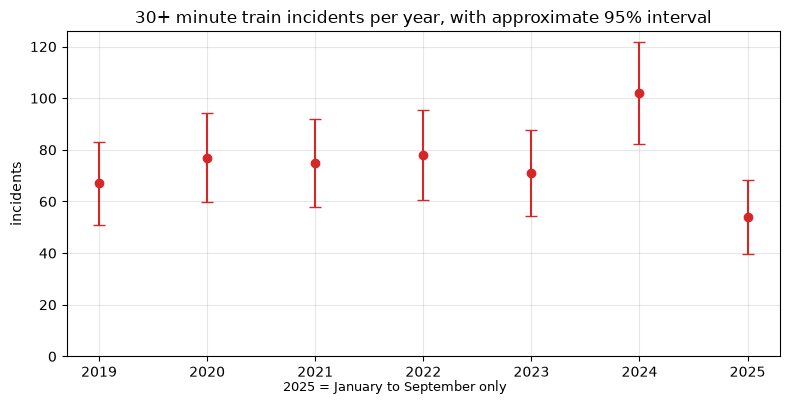

In [16]:
yearly = train.groupby("year").agg(severe=("y_30", "sum"), incidents=("y_30", "size"))
yearly["low"] = yearly["severe"] - 1.96 * np.sqrt(yearly["severe"])
yearly["high"] = yearly["severe"] + 1.96 * np.sqrt(yearly["severe"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(yearly.index, yearly["severe"],
            yerr=[yearly["severe"] - yearly["low"], yearly["high"] - yearly["severe"]],
            fmt="o", color="tab:red", capsize=4)
ax.set_xticks(yearly.index)
ax.set_title("30+ minute train incidents per year, with approximate 95% interval")
ax.set_xlabel("")
ax.set_ylabel("incidents")
ax.set_ylim(0, None)
fig.text(0.5, 0.01, "2025 = January to September only", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Finding.** The intervals for 2019–2023 overlap heavily: those years are statistically
indistinguishable, so a "worse year" headline built on them would mostly be noise.
2024 (102 events) is the only year that looks different, and even its interval almost
touches 2019's. 2025's 54 events cover nine months (about 72 on a full-year pace). Rare-event reporting should use
multi-year windows or rates with intervals, never single-year counts.

## 9. Summary: what this means for the modelling choices

| Question | Answer from the data | Implication |
|---|---|---|
| Where is the burden? | 30+ min incidents: < 2% of count, > 25% of delay minutes | A "rare, severe" target matches the CFO / Safety priorities |
| Are severe events different? | Yes: fire/smoke dominates the severe tail; rolling stock and doors dominate moderate delays | A 5-min model and a 30-min model rank different incidents |
| Is there a trade-off? | Yes, out of sample: tuning for 30+ min catches more severe events and fewer 5+ min ones | Pick the severe target deliberately; report the cost in moderate-delay recall |
| Does duration capture safety? | Mostly: most 30+ min events involve evacuation / power cut; ~1,000 shorter events also do | Duration target is a good proxy for safety; a safety-flag target is a possible alternative |
| How confident can we be? | ~80 severe events a year; yearly counts overlap within noise | Evaluate with uncertainty (e.g. bootstrap); report multi-year rates |
| What can't the data answer? | No ridership, no cost data, planned (not delivered) km | User impact and money can only be proxied by delay minutes |